# **Reproducible Least-Cost GIS Workflow: Cova de la Barriada**
---

<br>

# **Project Overview**

>This project develops a **parameterised and reproducible ArcGIS Pro Notebook workflow** to investigate the potential accessibility of the Gravettian palaeocoast from Cova de la Barriada, an archaeological site in Serra Gelada, Benidorm, Spain.

<br>

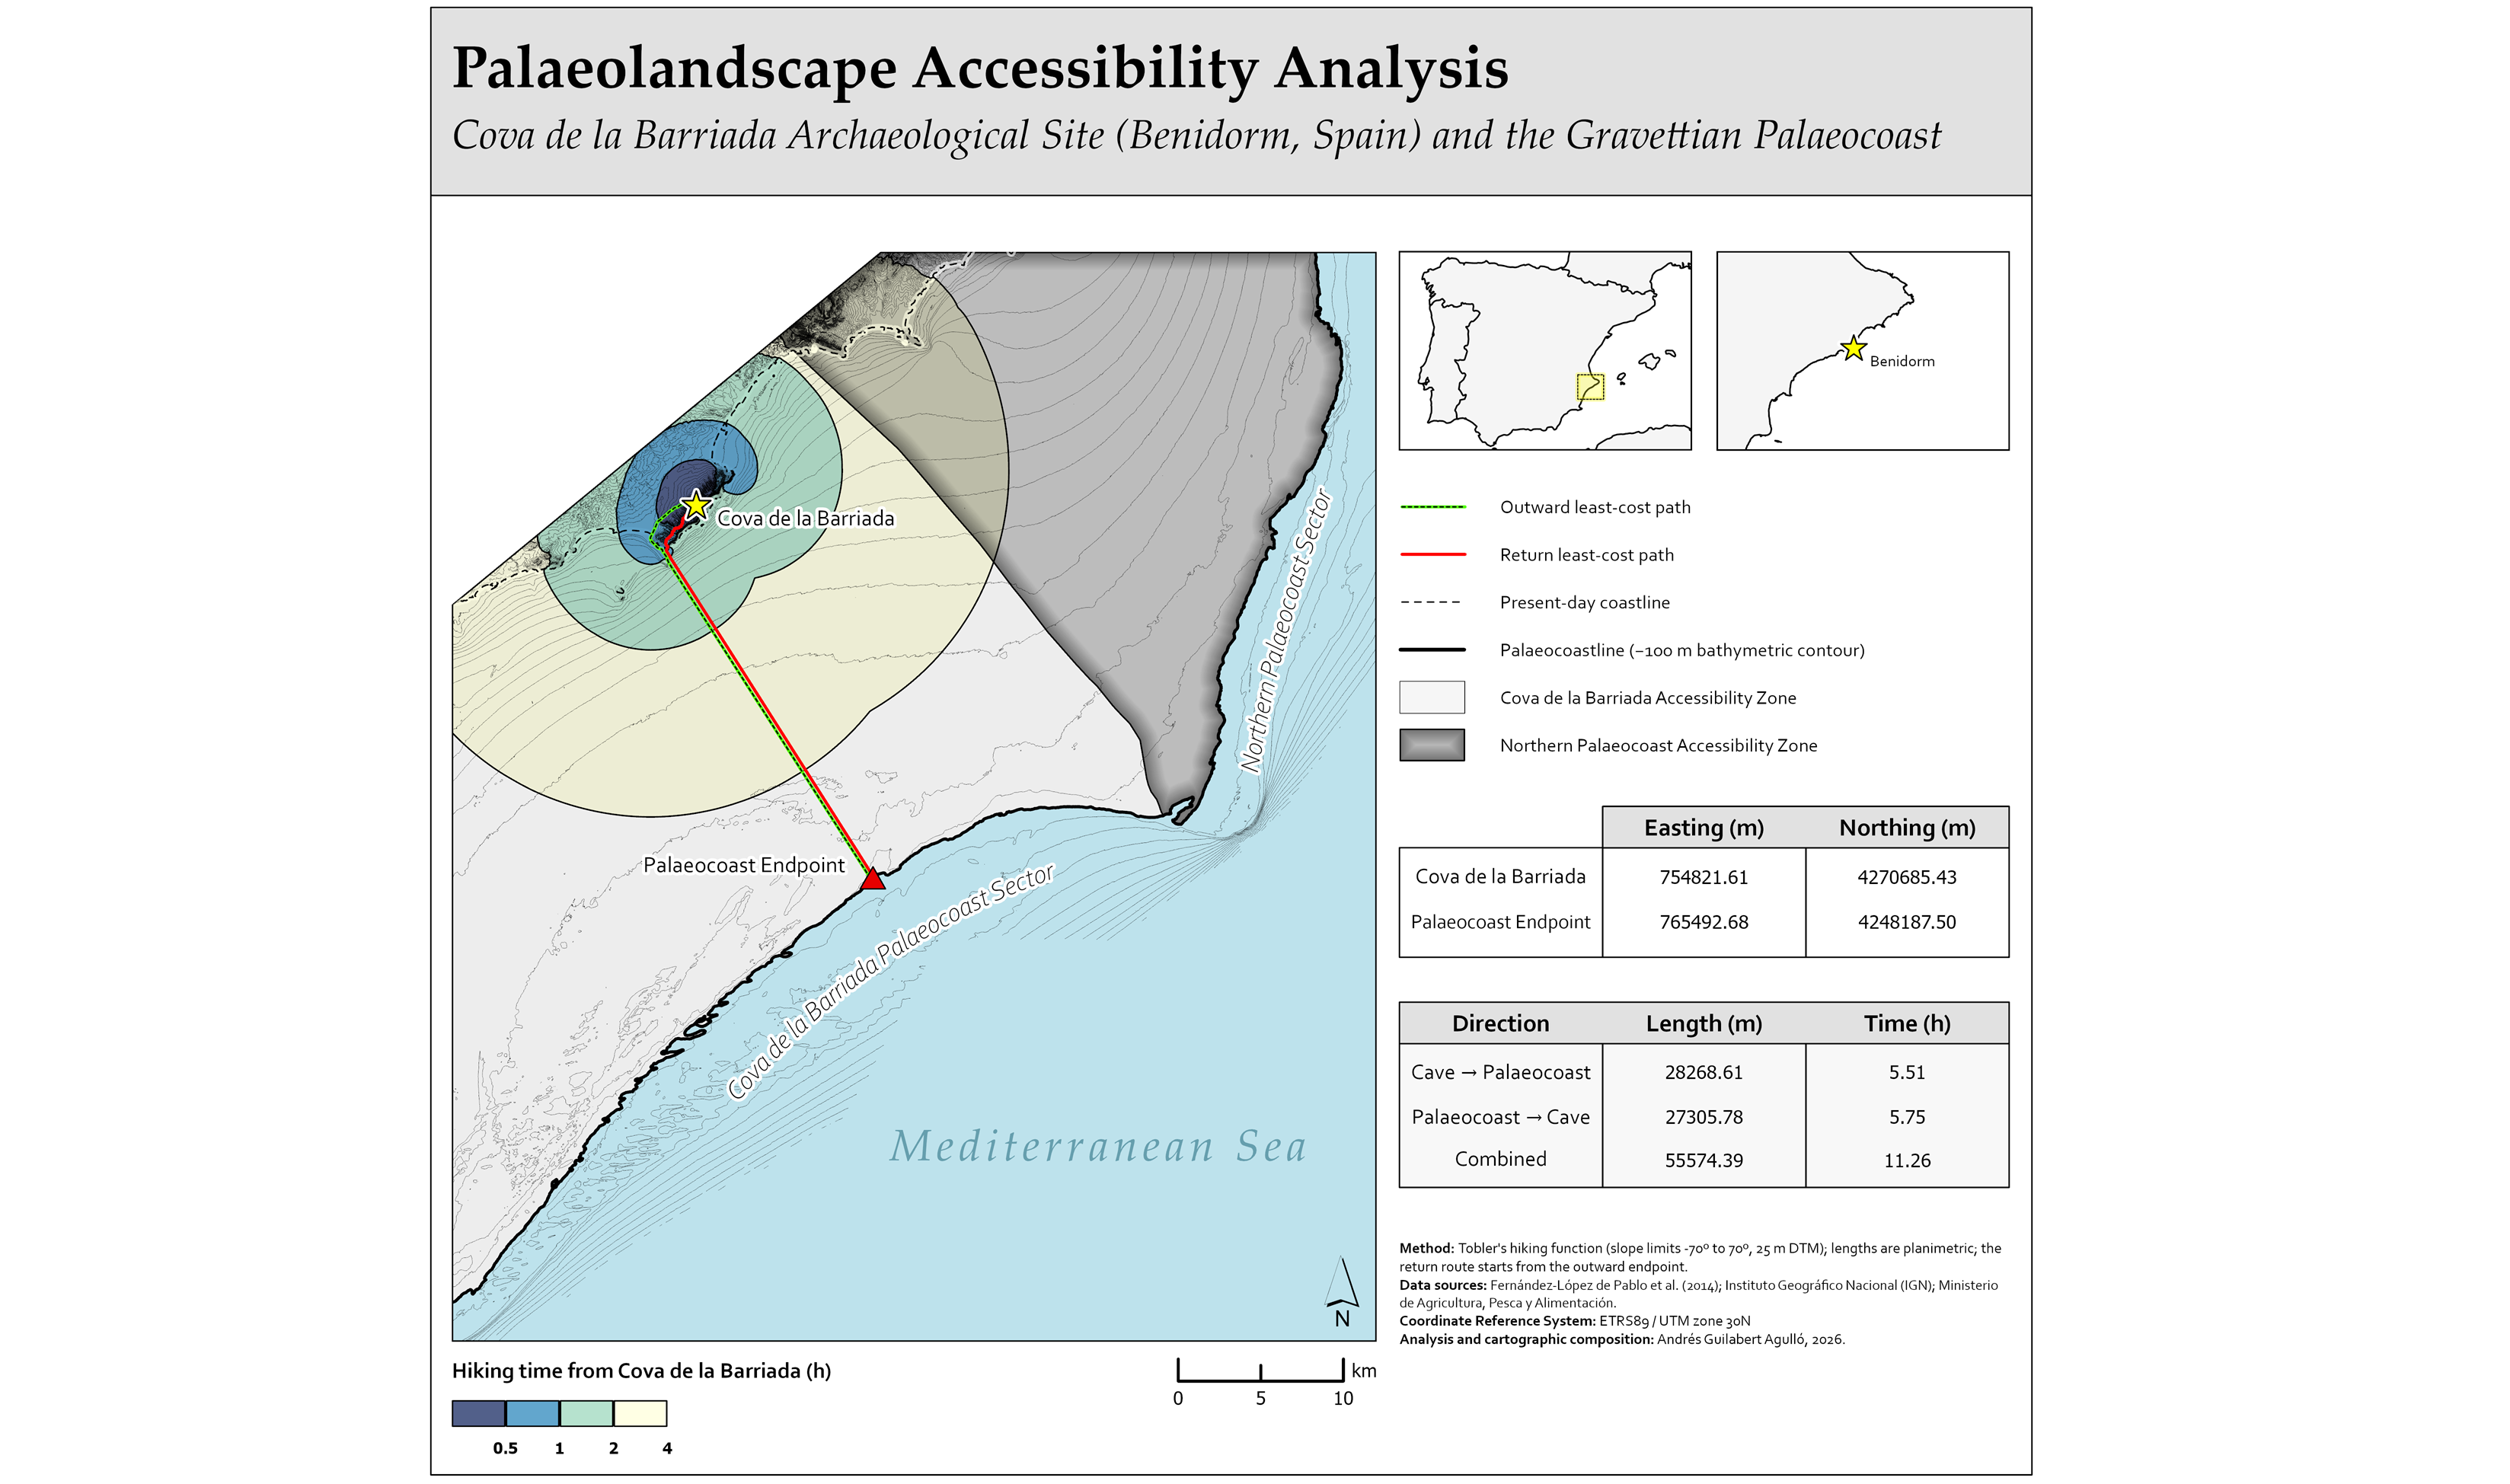

<br>

### **Case Study: Cova de la Barriada (*Barriada Cave*)**

> Archaeological evidence from *Cova de la Barriada* includes abundant remains of the land snail *Iberus alonensis*, interpreted as evidence of dietary diversification during the Early Upper Palaeolithic ([Fernández-López de Pablo et al., 2014](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0104898)). At the time, sea level was approximately **100 m below its present position**, placing the Mediterranean coastline considerably farther from the cave. Reconstructing the palaeolandscape and modelling access to the palaeocoast provide a spatial framework for investigating potential access to coastal resources.
>
> Using official topographic and bathymetric data, the workflow approximates the former coastline using the −100 m bathymetric contour. Terrain-based least-cost analysis compares access to different coastal sectors to identify the sector with the lowest modelled travel cost, its **Palaeocoast Endpoint** and the corresponding route from the cave.

### **Technical Design: Automation and Reproducibility**

> The workflow is designed for **automated, repeatable and configurable GIS processing**. Centralised parameters, project-relative paths and a dedicated staging geodatabase support consistent execution and structured management of intermediate and derived datasets. A dedicated `OUTPUT` directory stores the final datasets exported for external use.
>
> Parameterisation allows users to adjust three key modelling settings: DTM cell size, the slope-angle limits used in the Tobler hiking-time model, and the travel-time thresholds used to generate isochrones. These options provide flexibility in balancing terrain representation and processing requirements, adjusting the slope-angle limits used in the hiking-time model, and examining accessibility at different travel-time intervals. The workflow can be further extended to incorporate additional parameters, such as alternative palaeotopographic and palaeobathymetric inputs or environmental cost factors, as new data and modelling requirements emerge.
>
> The notebook also automates the generation of **intermediate figures and a final map layout** from analytical outputs, reducing manual processing, supporting quality control and keeping cartographic products consistent with the latest results.

### **Research Question**

> *Which sector of the Gravettian palaeocoast has the lowest modelled travel cost from Cova de la Barriada, and where is its Palaeocoast Endpoint and associated route?*

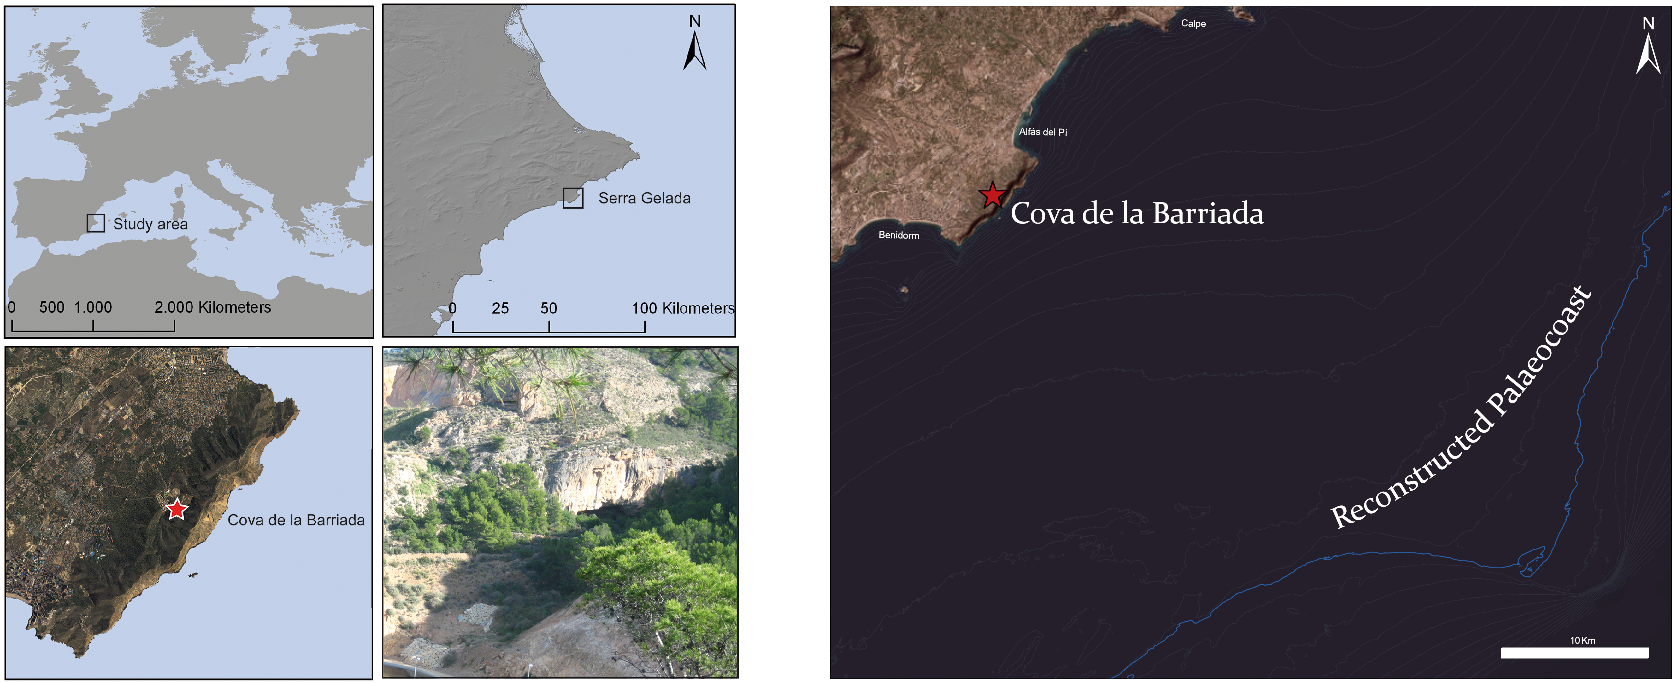
**Figure 1. Study area and reconstructed palaeocoast.**  
###### **Left:** Location map reproduced from Fernández-López de Pablo et al. (2014). **Right:** Project-generated contextual map showing the estimated palaeocoast location, with the −100 m bathymetric contour highlighted as a reference for its estimated offshore extent.

<br>
<br>

# **Workflow Setup and Configuration**
>This section allows users to customise three workflow parameters before execution: DTM resolution, hiking-time model slope limits, and isochrone travel-time thresholds. It also checks the availability of the ArcGIS Pro extensions required for processing.

### ▸ Workflow parameters definition

In [1]:
# =============================================================================
# USER-DEFINED WORKFLOW PARAMETERS
# =============================================================================

# --- DTM RESOLUTION ----------------------------------------------------------
# Set to 25 m to reproduce the final analysis (~20 min). Use a larger cell size
# for faster execution.
CELL_SIZE = 25

# --- HIKING-TIME MODEL SLOPE LIMITS ------------------------------------------
# Lower and upper slope-angle limits, in degrees.
# Slopes beyond these limits are assigned infinite travel cost.
VERTICAL_ANGLE_LIMITS = [-70, 70]


#--- ISOCHRONE TRAVEL-TIME THRESHOLDS ---------------------------------------------------------
#Travel-time thresholds (hours) used to generate the isochrone zones.
CONTOUR_VALUES = [0.5, 1, 2, 4, 5, 6]

### ▸ Workflow configuration

In [2]:
# =============================================================================
# WORKFLOW CONFIGURATION
# =============================================================================

import arcpy
from pathlib import Path
from IPython.display import display, Image, Markdown


# --- PROJECT SETUP -----------------------------------------------------------
aprx = arcpy.mp.ArcGISProject("CURRENT")
PROJECT_DIR = Path(aprx.homeFolder)

# Staging geodatabase for all intermediate and derived datasets
staged_gdb = PROJECT_DIR / "STAGING" / "STAGING.gdb"

if not staged_gdb.exists():
    staged_gdb.parent.mkdir(parents=True, exist_ok=True)
    arcpy.management.CreateFileGDB(str(staged_gdb.parent), staged_gdb.name)

new_database = {"databasePath": str(staged_gdb), "isDefaultDatabase": False}

if new_database not in aprx.databases:
    aprx.updateDatabases(aprx.databases + [new_database])


# --- GEOPROCESSING ENVIRONMENT -----------------------------------------------
def set_project_environment():
    """Shared environment: staging gdb, EPSG:25830, no Z/M, overwrite, not added to map"""
    return arcpy.EnvManager(
        addOutputsToMap=False,
        overwriteOutput=True,
        outputCoordinateSystem=arcpy.SpatialReference(25830),
        workspace=str(staged_gdb),
        scratchWorkspace=str(staged_gdb),
        outputZFlag="Disabled",
        outputMFlag="Disabled")

# --- DATASET PATH HELPER ----------------------------------------------------
def gdb_path(name):
    """Build the full path to a dataset in the staging geodatabase"""
    return str(staged_gdb / name)

# --- FIGURE HELPER -----------------------------------------------------------
def display_map_export(data_list, figure_name, scale=0.75):
    """Export staged datasets (bottom to top) as a PNG using STYLES/<name>.lyrx, then display it"""
    tmp_map = aprx.createMap("_tmp_figure")
    tmp_map.spatialReference = arcpy.SpatialReference(25830)
    cim = tmp_map.getDefinition("V3")
    cim.backgroundColor = {"type": "CIMRGBColor", "values": [255, 255, 255, 100]}  # set white blackground
    tmp_map.setDefinition(cim)

    for lyr in tmp_map.listLayers():            # remove default basemap
        tmp_map.removeLayer(lyr)

    for name in data_list:
        style_file = PROJECT_DIR / "STYLES" / f"{name}.lyrx"
        
        if not style_file.exists():
            raise FileNotFoundError(f"Missing style file: {style_file.name}")
       
        lyrx = arcpy.mp.LayerFile(str(style_file))
        lyr = tmp_map.addLayer(lyrx, "TOP")[0]
        if name == "isochrones_cave":
            sym = lyr.symbology
            sym.renderer.field = "ContourMax"
            lyr.symbology = sym

    output_path = PROJECT_DIR / "FIGURES" / f"{figure_name}.png"
    png = arcpy.mp.CreateExportFormat("PNG", str(output_path))
    png.width, png.height = round(png.width * scale), round(png.height * scale)
    tmp_map.defaultView.export(png)

    display(Image(filename=str(output_path)))
    aprx.deleteItem(tmp_map)


# --- CONFIGURATION VALIDATION ------------------------------------------------
#Check ArcGIS Pro extension availability
for extension in ["3D", "Spatial"]:
    if arcpy.CheckExtension(extension) != "Available":
        raise RuntimeError(f"Required extension '{extension}' is not available")

# Validate DTM cell size
# Must be a finite, positive numeric value
if not isinstance(CELL_SIZE, (int, float)) or CELL_SIZE <= 0:
    raise ValueError("CELL_SIZE must be a positive number")

# Check slope-angle limits
if not isinstance(VERTICAL_ANGLE_LIMITS, list) or len(VERTICAL_ANGLE_LIMITS) != 2:
    raise ValueError("VERTICAL_ANGLE_LIMITS must be a list containing exactly two values")

LOW_ANGLE, HIGH_ANGLE = VERTICAL_ANGLE_LIMITS
if not -90 <= LOW_ANGLE < HIGH_ANGLE <= 90:
    raise ValueError("VERTICAL_ANGLE_LIMITS must satisfy -90 <= lower < upper <= 90")

# Validate isochrone parameters
if not isinstance(CONTOUR_VALUES, list) or not CONTOUR_VALUES:
    raise ValueError("CONTOUR_VALUES must be a list containing at least one value")

if any(not isinstance(value, (int, float)) or value <= 0 for value in CONTOUR_VALUES):
    raise ValueError("CONTOUR_VALUES must contain only positive numbers.")

if CONTOUR_VALUES != sorted(CONTOUR_VALUES) or len(CONTOUR_VALUES) != len(set(CONTOUR_VALUES)):
    raise ValueError("CONTOUR_VALUES must be in ascending order and must not contain duplicate values")

print("Configuration validation completed successfully.")

Configuration validation completed successfully.


<br>

# **Data Acquisition**

>The workflow uses three categories of input datasets according to their origin and preparation: *external source datasets*, obtained from institutional sources; a *digitised input dataset*, representing the cave location digitised from a scientific publication; and six *predefined project datasets*, prepared specifically for this study.

#### - ***External Source Datasets***



| CONTINENTAL SHELF BATHYMETRY |
| --- |


| Group | Specification | Value |
| --- | --- | --- |
| **Identification** | `Dataset` | Bati_plata (Batimetría de la Plataforma Continental)|
| **Identification** | `Description` | Bathymetry of the Spanish continental shelf from the Marine Mapping project (MAPA) |
| **Identification** | `Purpose` | To represent the present-day seafloor elevation used to reconstruct the palaeocoast |
| **Source** | `Provider` | Ministerio de Agricultura, Pesca y Alimentación (MAPA)|
| **Source** | `Metadata URL` | https://www.mapama.gob.es/ide/metadatos/srv/spa/catalog.search#/metadata/b32aed3e-d6aa-4781-9efe-a94882049f41 |
| **Source** | `Download URL` | https://www.mapa.gob.es/app/descargas/descargafichero.aspx?f=plataforma-batimetria.zip |
| **Source** | `Date Accessed` | 25 July 2026 |
| **Source** | `License` | CC BY 4.0 |
| **Source** | `Source Authority` | Authoritative |
| **Spatial** | `Scale` | 1:50,000 |
| **Spatial** | `Coordinate Reference System` | GCS_ETRS_1989 (EPSG:4258) |
| **Spatial** | `Bounding Box` | [-9.545914, 35.867044, 3.854043, 44.132571] (original dataset)|
| **Structure** | `Dataset Type & Format` | Shapefile (polylines) |
| **Structure** | `Dataset Size` | Original: 1.39 GB; **clipped subset in repository:** 91.2 MB |
| **Storage** | `Dataset Path` | DATA/RAW/Bati_plata.shp |

<br>

| NATIONAL TOPOGRAPHIC BASE OF SPAIN |
| --- |


| Group | Specification | Value |
| --- | --- | --- |
| **Identification** | `Dataset` | BTN0201L_CUR_NIV (Base Topográfica Nacional de España - BTN Unidad - Alacant/Alicante) |
| **Identification** | `Description` | Contour lines from the National Topographic Base of Spain (BTN) for the province of Alicante |
| **Identification** | `Purpose` | To provide the terrestrial elevation contours used, together with the bathymetry, to build the DTM and reconstruct the palaeocoast |
| **Source** | `Provider` | Centro Nacional de Información Geográfica (CNIG), Instituto Geográfico Nacional (IGN) |
| **Source** | `Download Page URL` | https://centrodedescargas.cnig.es/CentroDescargas/detalleArchivo?sec=12165659 |
| **Source** | `Date Accessed` | 25 July 2026 |
| **Source** | `License` | CC BY 4.0 |
| **Source** | `Source Authority` | Authoritative |
| **Spatial** | `Scale` | 1:25,000 |
| **Spatial** | `Coordinate Reference System` | ETRS89 / UTM zone 30N (EPSG:25830) |
| **Spatial** | `Bounding Box` | [666409.299990, 4190936.100604, 787679.307262, 4317011.765370] (province of Alicante) |
| **Structure** | `Dataset Type & Format` | Shapefile (polylines) |
| **Structure** | `Dataset Size` | 436.7 MB; **clipped subset in repository:** 66.6 MB |
| **Storage** | `Dataset Path` | DATA/RAW/BTN0201L_CUR_NIV.shp |

#### - ***Digitised input dataset***

| BARRIADA CAVE LOCATION |
| --- |

| Group | Specification | Value |
| --- | --- | --- |
| **Identification** | `Dataset` | cave_location (Study Cave Location) |
| **Identification** | `Description` | Point feature with the approximate location of the study cave, digitised from the location map in the source publication |
| **Identification** | `Purpose` | To define the source location of the hiking-time accumulation and the optimal paths |
| **Source** | `Source Reference` | [Fernández-López de Pablo et al. (2014)](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0104898) |
| **Source** | `Date Accessed` | 25 July 2026 |
| **Source** | `License` | CC BY 4.0; digitised point: own work |
| **Source** | `Source Authority` | Peer-reviewed scientific publication |
| **Spatial** | `Coordinate Reference System` | ETRS89 / UTM zone 30N (EPSG:25830) |
| **Structure** | `Dataset Type & Format` | Shapefile (point) |
| **Structure** | `Dataset Size` | 1 feature |
| **Storage** | `Dataset Path` | DATA/REFERENCE/cave_location.shp |

<br>

#### - ***Predefined project layers***
<br>

| Dataset | Description |
| --- | --- |
| `project_extent` | Defines the overall study extent used to constrain spatial processing |
| `dtm_boundary` | Defines the area covered by the digital terrain model, excluding the northwestern mountainous sector |
| `dtm_coast` | Represents the terrestrial area landward of the reconstructed palaeocoast and constrains DTM interpolation along the coastal margin |
| `dtm_cliff` | Represents coastal cliffs and constrains DTM interpolation across abrupt elevation discontinuities |
| `palaeo_coast` | Modelled palaeocoast represented by the present-day −100 m bathymetric contour |
| `palaeo_coast_sectors` | Divides the reconstructed palaeocoast into sectors for the subsequent spatial analysis |


<br>
<br>

# **Data Preparation**

>This stage defines the project extent, standardises and integrates the topographic and bathymetric datasets, and generates a continuous terrestrial–marine digital terrain model (DTM) for the subsequent accessibility analysis.

### ▸ Project Extent Definition

The project extent was manually delineated in ArcGIS Pro using the datasets acquired during the Data Acquisition stage as the primary spatial reference. The −100 m depth contour provided a reference for defining the offshore limit. The resulting polygon was saved as `project_extent.shp` in `DATA/REFERENCE` and establishes the spatial framework for subsequent data preparation.

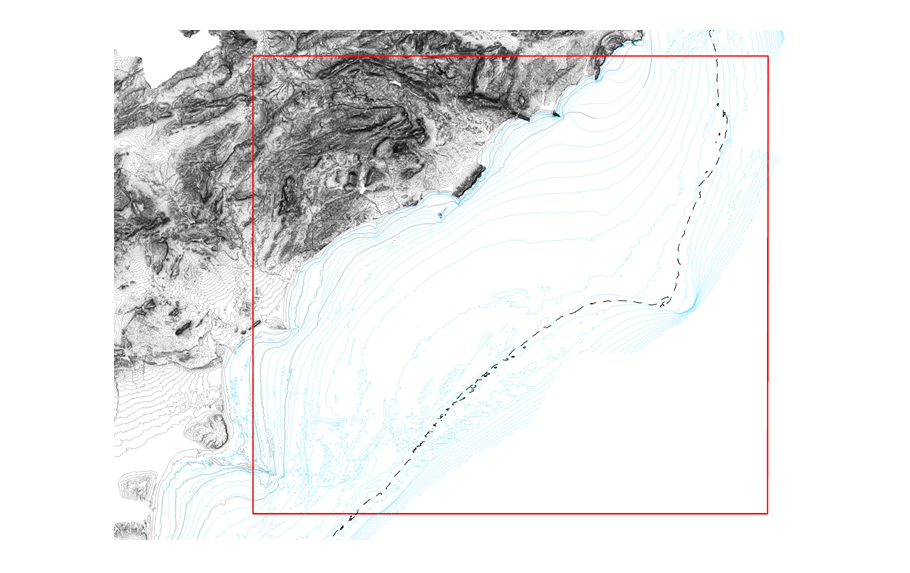  
**Figure 2. Project Extent Definition**
###### **Red:** Extent Boundary (*project_extent.shp*), **Blue:** Bathymetry Contours (*Bati_plata.shp*), **Black:** Topographic Contours (*BTN0201L_CUR_NIV.shp*), **Dashed Line:** Reconstructed Palaeocoast ( -100 m )  


<br>

### ▸ Data Standardisation and Integration

Source datasets in `DATA/RAW` and predefined reference datasets in `DATA/REFERENCE` are validated and copied to a staging geodatabase in the project coordinate system (`EPSG:25830`). The project extent is applied as a processing constraint.   

The national topographic dataset (`BTN0201L_CUR_NIV.shp`) is filtered to retain standard contour features (`TIPO_0201 = '01'`), excluding shallow bathymetric contours and other feature types in accordance with the [BTN Product Specifications](https://www.ign.es/resources/docs/IGNCnig/BTN/ESPBTN.pdf). Topographic and bathymetric elevation fields are standardised to `ELEVATION` before the datasets are merged into `extent_contours` for DTM interpolation. These merged contours are then clipped to `dtm_boundary` to produce `topo_bath_contours` for cartographic representation.

In [3]:
print("Starting data standardisation and integration...")

# --- EXTERNAL SOURCE DATA ------------------------------------------------
topo_raw = PROJECT_DIR / "DATA" / "RAW" / "BTN0201L_CUR_NIV.shp" # National topographic contours
bath_raw = PROJECT_DIR / "DATA" / "RAW" / "Bati_plata.shp" # Continental shelf bathymetric contours

# --- PREDEFINED PROJECT REFERENCE DATASETS -------------------------------
cave_reference = PROJECT_DIR / "DATA" / "REFERENCE" / "cave_location.shp" # Archaeological site
extent_reference = PROJECT_DIR / "DATA" / "REFERENCE" / "project_extent.shp" # Overall study extent
dtm_boundary = PROJECT_DIR / "DATA" / "REFERENCE" / "dtm_boundary.shp" # DTM interpolation boundary
dtm_coast = PROJECT_DIR / "DATA" / "REFERENCE" / "dtm_coast.shp" # Terrestrial palaeocoastal constraint
dtm_cliff = PROJECT_DIR / "DATA" / "REFERENCE" / "dtm_cliff.shp" # Coastal cliff constraint
palaeo_coast_sectors = PROJECT_DIR / "DATA" / "REFERENCE" / "palaeo_coast_sectors.shp" # Palaeocoast sectors
palaeo_coast = PROJECT_DIR / "DATA" / "REFERENCE" / "palaeo_coast.shp" # Reconstructed palaeocoast

# --- CHECK REQUIRED INPUTS -----------------------------------------------
required_datasets = {topo_raw : topo_raw.exists(),
                     bath_raw : bath_raw.exists(), 
                     cave_reference : cave_reference.exists(),
                     extent_reference : extent_reference.exists(),
                     dtm_boundary : dtm_boundary.exists(),
                     dtm_coast : dtm_coast.exists(),
                     dtm_cliff : dtm_cliff.exists(),
                     palaeo_coast : palaeo_coast.exists(), 
                     palaeo_coast_sectors : palaeo_coast_sectors.exists()}

                     
if not all (required_datasets.values()):
    missing = [path for path, exists in required_datasets.items() if not exists]
    raise FileNotFoundError("Missing required datasets:\n" + "\n".join(f"  - {path}" for path in missing))


# --- DEFINE STAGED DATASET NAMES --------------------------------------------
input_datasets = list(required_datasets.keys())
staged_names = ["topo_contours", "bath_contours", "cave_location", "project_extent", 
                "dtm_boundary", "dtm_coast", "dtm_cliff", "palaeo_coast", "palaeo_coast_sectors"]


# --- STANDARDISE AND STAGE DATASETS -----------------------------------------
# Run standardisation in the reusable project environment and apply the project extent as an additional spatial constraint
with set_project_environment():
    with arcpy.EnvManager(extent=str(extent_reference)):

        print (f"\nOUTPUT GEODATABASE:\n{staged_gdb}\n")
        
        for dataset, stg_name in zip(input_datasets, staged_names):
            
            # Topography: retain only standard contour lines (TIPO_0201 = '01'),
            # exclude bathymetric contours, and standardise the elevation field name.
            if dataset == topo_raw:
                d = arcpy.conversion.ExportFeatures(str(dataset), stg_name, where_clause="TIPO_0201 = '01'")
                arcpy.management.DeleteField(stg_name, "COTA_0201", "KEEP_FIELDS")
                arcpy.management.AlterField(stg_name, "COTA_0201", "ELEVATION", "ELEVATION")
    
            # Bathymetry: retain only the contour field and standardise its name
            # to ELEVATION to match the topographic dataset schema.
            elif dataset == bath_raw:
                d = arcpy.management.CopyFeatures(str(dataset), stg_name)
                arcpy.management.DeleteField(stg_name, "Contour", "KEEP_FIELDS")
                arcpy.management.AlterField(stg_name, "Contour", "ELEVATION", "ELEVATION")
    
            # Rest of datasets: copy without attribute schema modification.
            else:
                d = arcpy.management.CopyFeatures(str(dataset), stg_name)

            desc = arcpy.Describe(d[0])
            f_count = arcpy.management.GetCount(d[0])[0]
            print (f"{desc.name:<25} | {f_count:<5} features | {desc.shapeType:<8} | EPSG:{desc.spatialReference.factoryCode}")
            
   
        # Integrate the standardised topographic and bathymetric contours.
        d = arcpy.management.Merge([gdb_path("topo_contours"), gdb_path("bath_contours")], "extent_contours")
        
        desc = arcpy.Describe(d[0])
        f_count = arcpy.management.GetCount(d[0])[0]
        print (f"{desc.name:<25} | {f_count:<5} features | {desc.shapeType:<8} | EPSG:{desc.spatialReference.factoryCode}")

        # Clip the merged contours to the DTM boundary for cartographic representation.
        d = arcpy.analysis.Clip(gdb_path("extent_contours"), gdb_path("dtm_boundary"), "topo_bath_contours")

        desc = arcpy.Describe(d[0])
        f_count = arcpy.management.GetCount(d[0])[0]
        print (f"{desc.name:<25} | {f_count:<5} features | {desc.shapeType:<8} | EPSG:{desc.spatialReference.factoryCode}")
    
print("\nData standardisation and integration completed.")
    

Starting data standardisation and integration...

OUTPUT GEODATABASE:
C:\cova-barriada-gis-accessibility\STAGING\STAGING.gdb

topo_contours             | 10036 features | Polyline | EPSG:25830
bath_contours             | 25959 features | Polyline | EPSG:25830
cave_location             | 1     features | Point    | EPSG:25830
project_extent            | 1     features | Polygon  | EPSG:25830
dtm_boundary              | 1     features | Polygon  | EPSG:25830
dtm_coast                 | 1     features | Polygon  | EPSG:25830
dtm_cliff                 | 1     features | Polyline | EPSG:25830
palaeo_coast              | 1     features | Polyline | EPSG:25830
palaeo_coast_sectors      | 2     features | Polyline | EPSG:25830
extent_contours           | 35995 features | Polyline | EPSG:25830
topo_bath_contours        | 17441 features | Polyline | EPSG:25830

Data standardisation and integration completed.


<br>

### ▸ Digital Terrain Model

The digital terrain model (DTM) is generated using ArcGIS Pro's `TopoToRaster` tool, which interpolates a hydrologically consistent elevation surface from contour data and supporting spatial constraints. Four inputs guide the interpolation:

* **`extent_contours`** provides the elevation-controlling data, combining topographic and bathymetric contours with elevations stored in the `ELEVATION` field.

* **`dtm_boundary`** defines the DTM extent, excluding the northwestern mountainous sector, which would increase computational cost without contributing relevant information to the mobility analysis. It was created by refining a copy of `project_extent` through manual geometry editing. Its smaller extent allows contours beyond the output boundary to contribute elevation information to the interpolation.

* **`dtm_coast`** constrains the interpolated surface along the reconstructed palaeocoast, corresponding to the −100 m bathymetric contour. It represents the terrestrial area landward of the palaeocoast. The separate `palaeo_coast` line defines the reconstructed coastline used as the destination feature in the subsequent `Optimal Path As Line` analysis.

* **`dtm_cliff`** represents coastal cliffs and constrains interpolation across abrupt elevation discontinuities. The line is oriented so that lower elevations lie to the left and higher elevations to the right when following its direction.

The final DTM uses a 25 m cell size. The relatively gradual offshore bathymetric gradient means that finer resolution would add limited meaningful elevation detail. The final DTM is generated at a 25 m cell size. As this resolution requires approximately 15 minutes to process, a larger cell size can be used to reduce execution time.

The `tolerance_1` and `tolerance_2` parameters are set to 5 m and 100 m, respectively, following the recommended values for contour-based inputs.

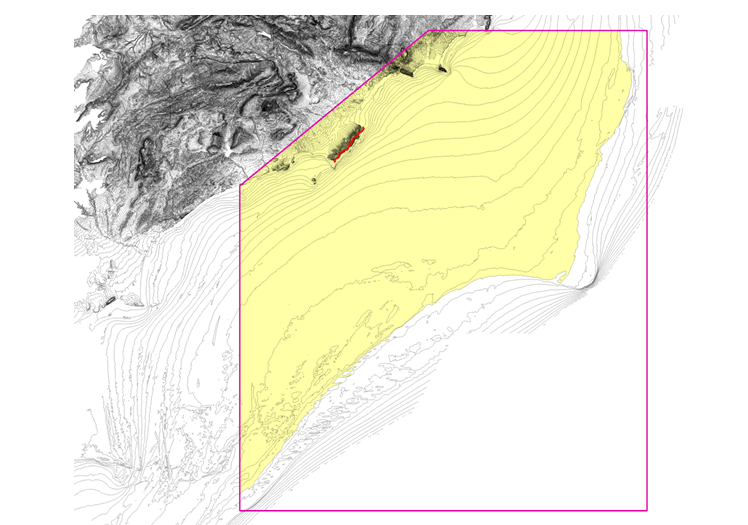  
**Figure 3. Spatial Inputs and Constraints for DTM Generation.**   
###### **Red:** Coastal cliff constraint (*dtm_cliff*); **Pink:** DTM boundary (*dtm_boundary*); **Black:** Elevation contours (*extent_contours*); **Yellow:** Palaeocoastal constraint (*dtm_coast*)

Starting DTM generation. This may take several minutes...

Output: C:\cova-barriada-gis-accessibility\STAGING\STAGING.gdb\dtm
Cell size: 25 m
Elevation range: -101.279861450195 m to 529.827941894531 m



**Figure 4. Generated Digital Terrain Model (DTM). Cell size: 25 m.**

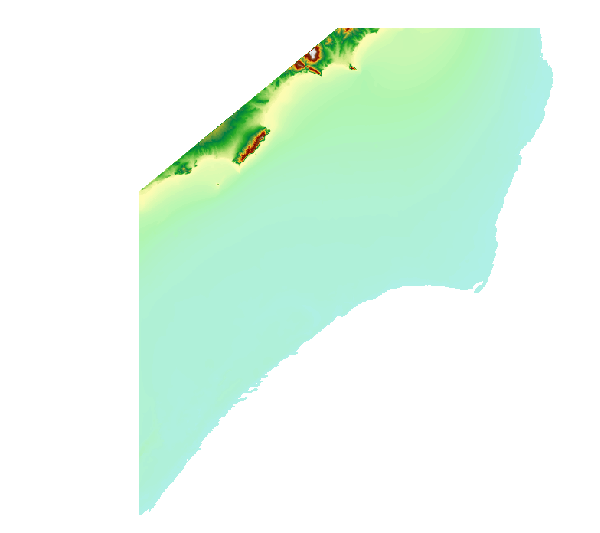

In [4]:
print("Starting DTM generation. This may take several minutes...\n")

# --- GENERATE DIGITAL TERRAIN MODEL ------------------------------------
# Run interpolation in the reusable project environment
# Apply the project extent as an additional spatial constraint

with set_project_environment():
    with arcpy.EnvManager(extent=str(extent_reference)):
                

        # Define interpolation inputs and feature roles.
        topo_inputs = (
            f"{gdb_path('extent_contours')} ELEVATION CONTOUR; "
            f"{gdb_path('dtm_boundary')} # BOUNDARY; "
            f"{gdb_path('dtm_coast')} # COAST; "
            f"{gdb_path('dtm_cliff')} # CLIFF"
        )
        
        # Generate the DTM using the contour-specific tolerance settings
        arcpy.ddd.TopoToRaster(in_topo_features=topo_inputs,
                               out_surface_raster="dtm_raw",
                               cell_size=CELL_SIZE,
                               data_type="CONTOUR",
                               tolerance_1=5,
                               tolerance_2=100)
        
        # Copy the generated raster to create the analysis-ready DTM
        arcpy.management.CopyRaster(gdb_path("dtm_raw"), "dtm")


        # --- REPORT DTM PROPERTIES ---------------------------------------------
        cell_x = arcpy.management.GetRasterProperties(gdb_path("dtm"),'CELLSIZEX')[0]
        cell_max = arcpy.management.GetRasterProperties(gdb_path("dtm"),'MAXIMUM')[0]
        cell_min = arcpy.management.GetRasterProperties(gdb_path("dtm"),'MINIMUM')[0]
        
        print(f"Output: {gdb_path("dtm")}")
        print(f"Cell size: {cell_x} m")
        print(f"Elevation range: {cell_min} m to {cell_max} m\n")
        
display(Markdown(f"**Figure 4. Generated Digital Terrain Model (DTM). Cell size: {float(cell_x):g} m.**"))
arcpy.Render(arcpy.Raster(gdb_path("dtm")), colormap="Elevation #1")



<br>
<br>

# **Data Modelling**
>This phase models accessibility across the reconstructed landscape through three complementary analyses: bidirectional least-time routes between the cave and the palaeocoast, travel-time isochrones around the cave,  and the spatial allocation of the study area to the two palaeocoast sectors according to accumulated travel time.

### ▸ Bidirectional Least-Time Route Modelling

`Distance Accumulation` calculates accumulated travel-time surfaces and back-direction rasters from `cave_location` and `dtm_cliff` barrier constraints. The `dtm` raster serves as both the surface and vertical input, while the `Hiking Time` vertical factor, based on Tobler's hiking function, accounts for slope-dependent walking speed and the directional asymmetry of uphill and downhill travel. A planar distance method calculates horizontal distances on the projected coordinate plane.

`Optimal Path As Line` derives the least-time route from `cave_location` to `palaeo_coast`. The coastal endpoint is extracted as `coast_endpoint` and used as the source for a second `Distance Accumulation` calculation, from which the return route to `cave_location` is derived. 

Starting Least-Time Route Analysis. This may take several minutes...



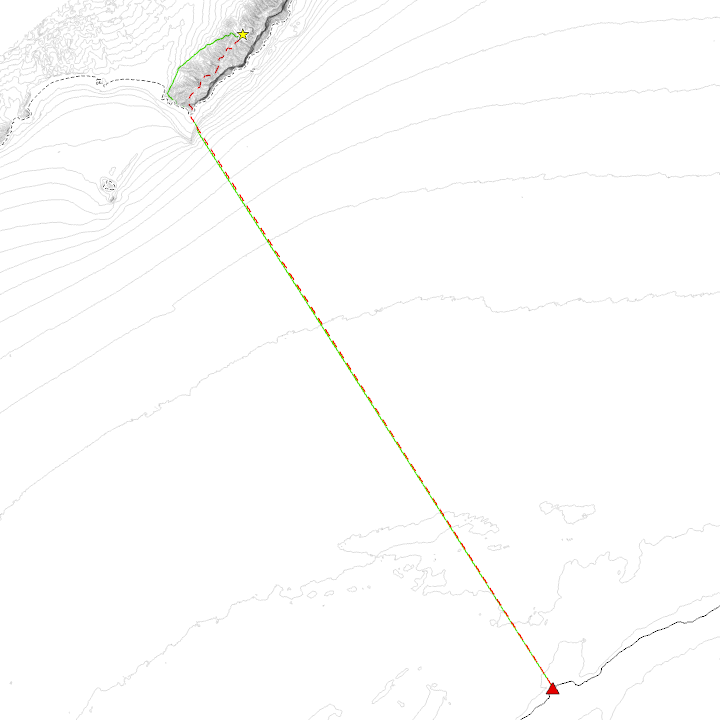

<br>

| Output                      | Value |
| --------------------------- | -----: |
| Cave location (*Star*) | 754821.61 m, 4270685.43 m |
| Coast endpoint (*Triangle*) | 765492.68 m, 4248187.50 m |
| Palaeocoast nearest sector | Southern |
| Outward travel length (*Green*) | 28268.61 m |
| Outward travel time (*Green*) | 5.51 h |
| Return travel length (*Red*) | 27305.78 m |
| Return travel time (*Red*) | 5.75 h |
| **Round-trip travel time**  | **11.26 h** |
 

**Figure 5. Cave-to-coast routes and travel-time summary**:
###### **Green:** Outward Path; **Red:** Return Path; **Triangle:** Coast Endpoint; **Star:** Cave Location

In [16]:
print("Starting Least-Time Route Analysis. This may take several minutes...\n")

# --- CALCULATE OUTWARD LEAST-TIME ROUTE ------------------------------------------------
# Run the analysis in the reusable project environment
with set_project_environment():
    
    # Calculate accumulated travel time raster from the cave
    # Account for terrain slope and cliff barriers.
    arcpy.sa.DistanceAccumulation(
        in_source_data=gdb_path("cave_location"),
        in_barrier_data=gdb_path("dtm_cliff"),
        in_surface_raster=gdb_path("dtm"),
        in_vertical_raster=gdb_path("dtm"),
        vertical_factor=arcpy.sa.VfHikingTime(LOW_ANGLE, HIGH_ANGLE),
        distance_method="PLANAR",
        out_back_direction_raster=gdb_path("back_direction_cave")
    ).save("dist_accum_cave")

    # Generate the least-time route from the cave to the palaeocoast
    arcpy.sa.OptimalPathAsLine(in_destination_data=gdb_path("palaeo_coast"),
                               in_distance_accumulation_raster=gdb_path("dist_accum_cave"), 
                               in_back_direction_raster=gdb_path("back_direction_cave"),
                               out_polyline_features=gdb_path("optimal_path_CAVE_COAST"))

    
    # --- CREATE COASTAL ENDPOINT --------------------------------------------------------
    # Extract the coastal endpoint
    coast_endpoint = gdb_path("coast_endpoint")
    if arcpy.Exists(coast_endpoint):
        arcpy.management.Delete(coast_endpoint)
        
    with arcpy.da.SearchCursor(gdb_path("optimal_path_CAVE_COAST"), ["SHAPE@"]) as cursor:
        path_geometry = next(cursor)[0]

    coast_endpoint_geom = path_geometry.firstPoint

    # Store the coastal endpoint as a point feature
    arcpy.management.CreateFeatureclass(str(staged_gdb), "coast_endpoint", "POINT", spatial_reference=arcpy.SpatialReference(25830))
    arcpy.management.AddField(gdb_path("coast_endpoint"), "TYPE", "TEXT", field_length=20)

    with arcpy.da.InsertCursor(gdb_path("coast_endpoint"), ["TYPE", "SHAPE@"]) as cursor:
        cursor.insertRow(["ENDPOINT", coast_endpoint_geom])

    
    # --- IDENTIFY NEAREST PALAEOCOAST SECTOR ---------------------------------------------
    # Assigns the nearest palaeocoast sector based on its OBJECTID
    arcpy.analysis.Near(gdb_path("coast_endpoint"), gdb_path("palaeo_coast_sectors"))
    with arcpy.da.SearchCursor (gdb_path("coast_endpoint"), ["NEAR_FID"]) as cursor:
        near_fid = next(cursor)[0]
        NEAR_SECTOR = "Southern" if near_fid == 1 else "Northern" if near_fid == 2 else "Unknown"

    
    # --- CALCULATE RETURN LEAST-TIME ROUTE -----------------------------------------------
    # Calculate accumulated travel time from the coastal endpoint
    arcpy.sa.DistanceAccumulation(
        in_source_data=gdb_path("coast_endpoint"),
        in_barrier_data=gdb_path("dtm_cliff"),
        in_surface_raster=gdb_path("dtm"),
        in_vertical_raster=gdb_path("dtm"),
        vertical_factor=arcpy.sa.VfHikingTime(LOW_ANGLE, HIGH_ANGLE),
        distance_method="PLANAR",
        out_back_direction_raster=gdb_path("back_direction_coast")
    ).save(gdb_path("dist_accum_coast"))

    # Generate the least-time return route from the palaeocoast to the cave
    arcpy.sa.OptimalPathAsLine(in_destination_data=gdb_path("cave_location"),
                               in_distance_accumulation_raster=gdb_path("dist_accum_coast"),
                               in_back_direction_raster=gdb_path("back_direction_coast"),
                               out_polyline_features=gdb_path("optimal_path_COAST_CAVE"))



    # --- SUMMARISE ROUTE METRICS ---------------------------------------------------------
    # Retrieve travel times and route lengths
    with arcpy.da.SearchCursor(gdb_path("optimal_path_CAVE_COAST"), ["PathCost", "SHAPE@LENGTH"]) as cursor:
        time_outward, length_outward = next(cursor)

    with arcpy.da.SearchCursor(gdb_path("optimal_path_COAST_CAVE"), ["PathCost", "SHAPE@LENGTH"]) as cursor:
        time_return, length_return = next(cursor)

    time_outward_rounded = round(time_outward, 2)
    time_return_rounded = round(time_return, 2)
    length_outward_rounded = round(length_outward,2)
    length_return_rounded = round(length_return,2)
    
    # Retrieve coastal endpoint coordinates.
    with arcpy.da.SearchCursor(gdb_path("coast_endpoint"), ["SHAPE@X", "SHAPE@Y"]) as cursor:
        x_coast, y_coast = next(cursor)

    # Retrieve cave location coordinates.
    with arcpy.da.SearchCursor(gdb_path("cave_location"), ["SHAPE@X", "SHAPE@Y"]) as cursor:
        x_cave, y_cave = next(cursor)


    # --- VISUALISE ROUTES AND REPORT RESULTS --------------------------------------------------
    display_map_export(["optimal_path_CAVE_COAST", "optimal_path_COAST_CAVE", "topo_bath_contours", "cave_location", "coast_endpoint"], "5_LEAST_TIME_ROUTES")      

display(Markdown(f"""<br>

| Output                      | Value |
| --------------------------- | -----: |
| Cave location (*Star*) | {x_cave:.2f} m, {y_cave:.2f} m |
| Coast endpoint (*Triangle*) | {x_coast:.2f} m, {y_coast:.2f} m |
| Palaeocoast nearest sector | {NEAR_SECTOR} |
| Outward travel length (*Green*) | {length_outward_rounded:.2f} m |
| Outward travel time (*Green*) | {time_outward_rounded:.2f} h |
| Return travel length (*Red*) | {length_return_rounded:.2f} m |
| Return travel time (*Red*) | {time_return_rounded:.2f} h |
| **Round-trip travel time**  | **{(time_outward_rounded + time_return_rounded):.2f} h** |
 """))

display(Markdown("""**Figure 5. Cave-to-coast routes and travel-time summary**:
###### **Green:** Outward Path; **Red:** Return Path; **Triangle:** Coast Endpoint; **Star:** Cave Location"""))

<br>

### ▸ Cave Accessibility Isochrones

Travel-time isochrone zones were derived from the accumulated travel-time raster generated from the cave location. User-defined travel-time thresholds determine the boundaries of successive accessibility zones. The `ContourList` tool generates polygon zones, which are filtered to retain only those corresponding to the specified thresholds. 

Starting Isochrone Zones generation...


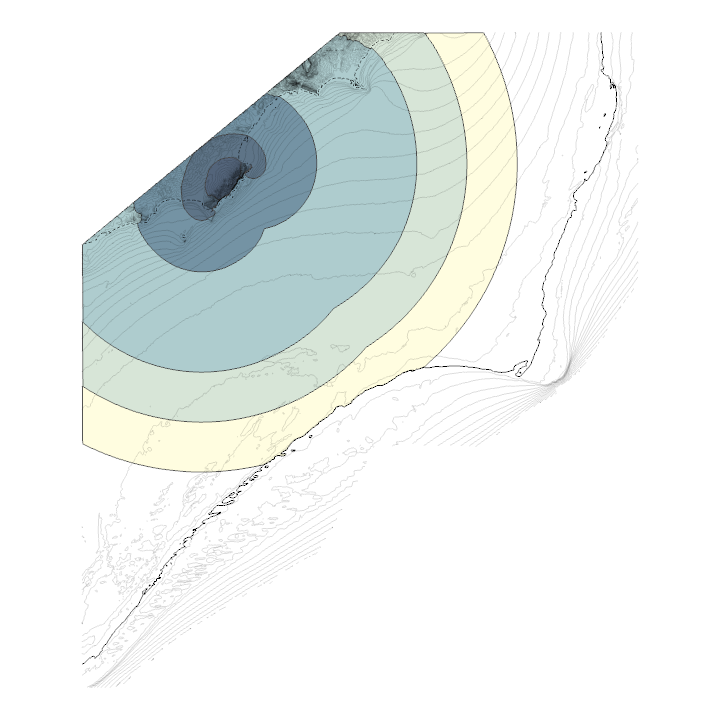

**Figure 6. Travel-time isochrone zones**: (0.5, 1, 2, 4, 5, 6) hours

In [7]:
print ("Starting Isochrone Zones generation...")

# --- GENERATE ISOCHRONE ZONES ---------------------------------------------------------------
# Run the analysis in the reusable project environment
with set_project_environment():
        
    # Remove the previous output to ensure a clean regeneration
    if arcpy.Exists(gdb_path("isochrones_cave")):
        arcpy.management.Delete(gdb_path("isochrones_cave"))
        
    # Generate polygon isochrone zones from the cave accessibility raster 
    arcpy.sa.ContourList(gdb_path("dist_accum_cave"), "isochrones_cave_stg", CONTOUR_VALUES, contour_type="CONTOUR_POLYGON")

    # Retain only polygons corresponding to the specified travel-time thresholds
    values_string = f'{str(CONTOUR_VALUES).replace("[","(").replace("]",")")}'
    where = f'"ContourMax" NOT IN {values_string}'
    with arcpy.da.UpdateCursor(gdb_path("isochrones_cave_stg"), ["ContourMax"], where_clause=where) as cursor:
        for row in cursor:
            cursor.deleteRow()
    
    arcpy.management.CopyFeatures(gdb_path("isochrones_cave_stg"), "isochrones_cave")

    display_map_export(["topo_bath_contours", "isochrones_cave"], "6_ISOCHRONES_CAVE")
    display(Markdown(f"""**Figure 6. Travel-time isochrone zones**: {values_string} hours"""))
                     

<br>

### ▸ Palaeocoast Accessibility Zonation

The reconstructed palaeocoast was divided into two sectors during project preparation, stored in the predefined `palaeo_coast_sectors` dataset. The segmentation point (0.2410419°E, 38.3708669°N) was identified through visual inspection of the isochrones and the ridge in the `dist_accum_coast` surface, which indicates a transition in relative travel-time accessibility between coastal locations. The point was placed where this ridge intersects the palaeocoast. This preparatory step was completed before the main workflow and is not generated by the code presented here.

`Distance Allocation` assigns locations across the study area to the coastal sector with the lowest accumulated travel cost, using the `SECTOR` field to identify each source. The analysis accounts for terrain elevation, cliff barriers and slope-dependent walking costs.

In [8]:
print ("Starting Distance Allocation...")

# --- GENERATE DISTANCE ALLOCATION ---------------------------------------
# Run the analysis in the reusable project environment
with set_project_environment():

    # Calculate terrain-based accessibility allocation to palaeocoast sectors
    # using cliff barriers and hiking-time effects.
    arcpy.sa.DistanceAllocation(in_source_data=gdb_path("palaeo_coast_sectors"),
                                source_field="SECTOR",
                                in_barrier_data=gdb_path("dtm_cliff"),
                                in_surface_raster=gdb_path("dtm"),
                                in_vertical_raster=gdb_path("dtm"),
                                vertical_factor=arcpy.sa.VfHikingTime(LOW_ANGLE, HIGH_ANGLE),
                                distance_method="PLANAR").save("allocation_coast")

    # Convert the accessibility allocation raster to polygons for cartographic use.
    arcpy.conversion.RasterToPolygon(in_raster=gdb_path("allocation_coast"),
                                     out_polygon_features="allocation_coast_polygon",
                                     simplify="SIMPLIFY")
                                     
                                     
                                     
print ("Distance Allocation completed.") 

Starting Distance Allocation...
Distance Allocation completed.


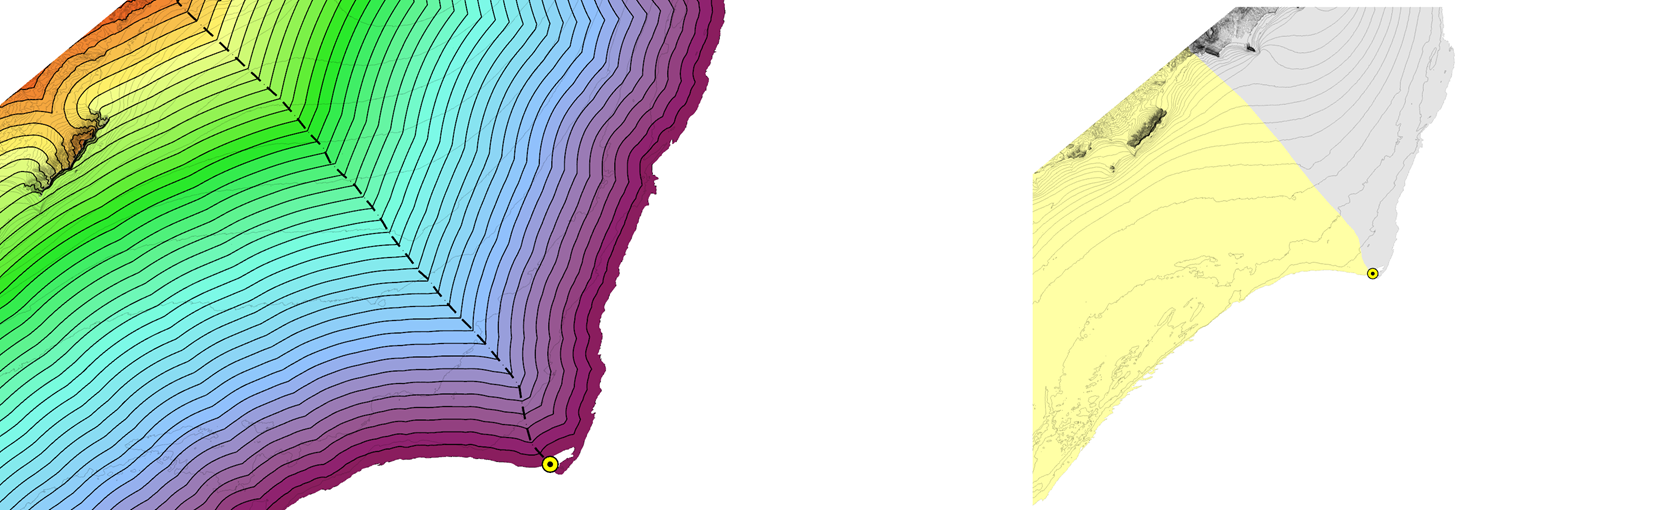

**Figure 7. Palaeocoast accessibility zonation.**  
###### **Left:** Identification of the segmentation point, carried out beforehand and provided as reference data (not part of the workflow): accumulated travel time from the palaeocoast (dist_accum_coast) with isochrones. The dashed line marks the ridge where the nearest coastal location changes; the point (yellow) is placed where this ridge meets the palaeocoast; **Right:** Distance Allocation result: areas reached in the least accumulated travel time from th southern sector (yellow) or the northern sector (grey). The cave location plays no role in either panel.

<br>

# **Results and Outputs**

### ▸ Final Datasets
The final datasets are exported as shapefiles to the `OUTPUT`, primarily to support cartographic composition and external use. The exported datasets include the topographic and bathymetric contours, accessibility sectors, travel-time isochrones, bidirectional least-time paths, palaeocoast endpoint, cave location, and supporting terrain boundaries.


In [9]:
print ("Starting Datasets Export...\n")

# Run the analysis in the reusable project environment
with set_project_environment():    
        
    # --- DEFINE EXPORT DATASETS -------------------------------------
    datasets = ["topo_bath_contours","allocation_coast_polygon",
                "isochrones_cave", "dtm_coast", "optimal_path_CAVE_COAST",
                "optimal_path_COAST_CAVE", "coast_endpoint", "dtm_boundary", "cave_location"]
    
    DATASETS_PATH  = [staged_gdb / dataset_name for dataset_name in datasets]

    # --- EXPORT DATASETS AS SHAPEFILES ------------------------------
    OUTPUT_DIR = PROJECT_DIR / "OUTPUT"
    if not OUTPUT_DIR.exists():
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
       
    OUTPUT_DATASETS_PATH = [str( OUTPUT_DIR / f"{dataset_name}.shp") for dataset_name in datasets]

    for dataset_path, output_path in zip(DATASETS_PATH, OUTPUT_DATASETS_PATH):
        arcpy.conversion.ExportFeatures(dataset_path, output_path)
        print (f"{dataset_path.name:<25} | {output_path}")
            
print ("\nDatasets Export completed.")

            


Starting Datasets Export...

topo_bath_contours        | C:\cova-barriada-gis-accessibility\OUTPUT\topo_bath_contours.shp
allocation_coast_polygon  | C:\cova-barriada-gis-accessibility\OUTPUT\allocation_coast_polygon.shp
isochrones_cave           | C:\cova-barriada-gis-accessibility\OUTPUT\isochrones_cave.shp
dtm_coast                 | C:\cova-barriada-gis-accessibility\OUTPUT\dtm_coast.shp
optimal_path_CAVE_COAST   | C:\cova-barriada-gis-accessibility\OUTPUT\optimal_path_CAVE_COAST.shp
optimal_path_COAST_CAVE   | C:\cova-barriada-gis-accessibility\OUTPUT\optimal_path_COAST_CAVE.shp
coast_endpoint            | C:\cova-barriada-gis-accessibility\OUTPUT\coast_endpoint.shp
dtm_boundary              | C:\cova-barriada-gis-accessibility\OUTPUT\dtm_boundary.shp
cave_location             | C:\cova-barriada-gis-accessibility\OUTPUT\cave_location.shp

Datasets Export completed.


<br>

### ▸ Map Preparation

The workflow imports predefined ArcGIS Pro map and layout templates, applies the isochrone symbology and updates layout text with route lengths, travel times, endpoint coordinates and analysis parameters. The final layout is exported as a 600 dpi PNG to `OUTPUT/LAYOUT.png` and displayed in the notebook.

In [10]:
print ("Removing existing map and layout, if any...")

# --- DEFINE MAP AND LAYOUT TEMPLATES -----------------------------------
map_template = PROJECT_DIR / "TEMPLATES" / "COVA_BARRIADA_MAP.mapx"
layout_template = PROJECT_DIR / "TEMPLATES" / "COVA_BARRIADA_LAYOUT.pagx"

# --- VALIDATE TEMPLATE FILES -------------------------------------------
if not map_template.exists() or not layout_template.exists():
    raise FileNotFoundError("Map or layout template not found")

# --- REMOVE EXISTING MAP AND LAYOUT -------------------------------------
# Prevent duplicate items in the ArcGIS Pro project.

for layout_obj in aprx.listLayouts("COVA_BARRIADA_LAYOUT"):
    aprx.deleteItem(layout_obj)
    
for map_obj in aprx.listMaps("COVA_BARRIADA_MAP"):
    aprx.deleteItem(map_obj)

print("Existing map and layout removed successfully")


Removing existing map and layout, if any...
Existing map and layout removed successfully


Starting Map and Layout Import...

Output Layout Path: C:\cova-barriada-gis-accessibility\OUTPUT\LAYOUT.png



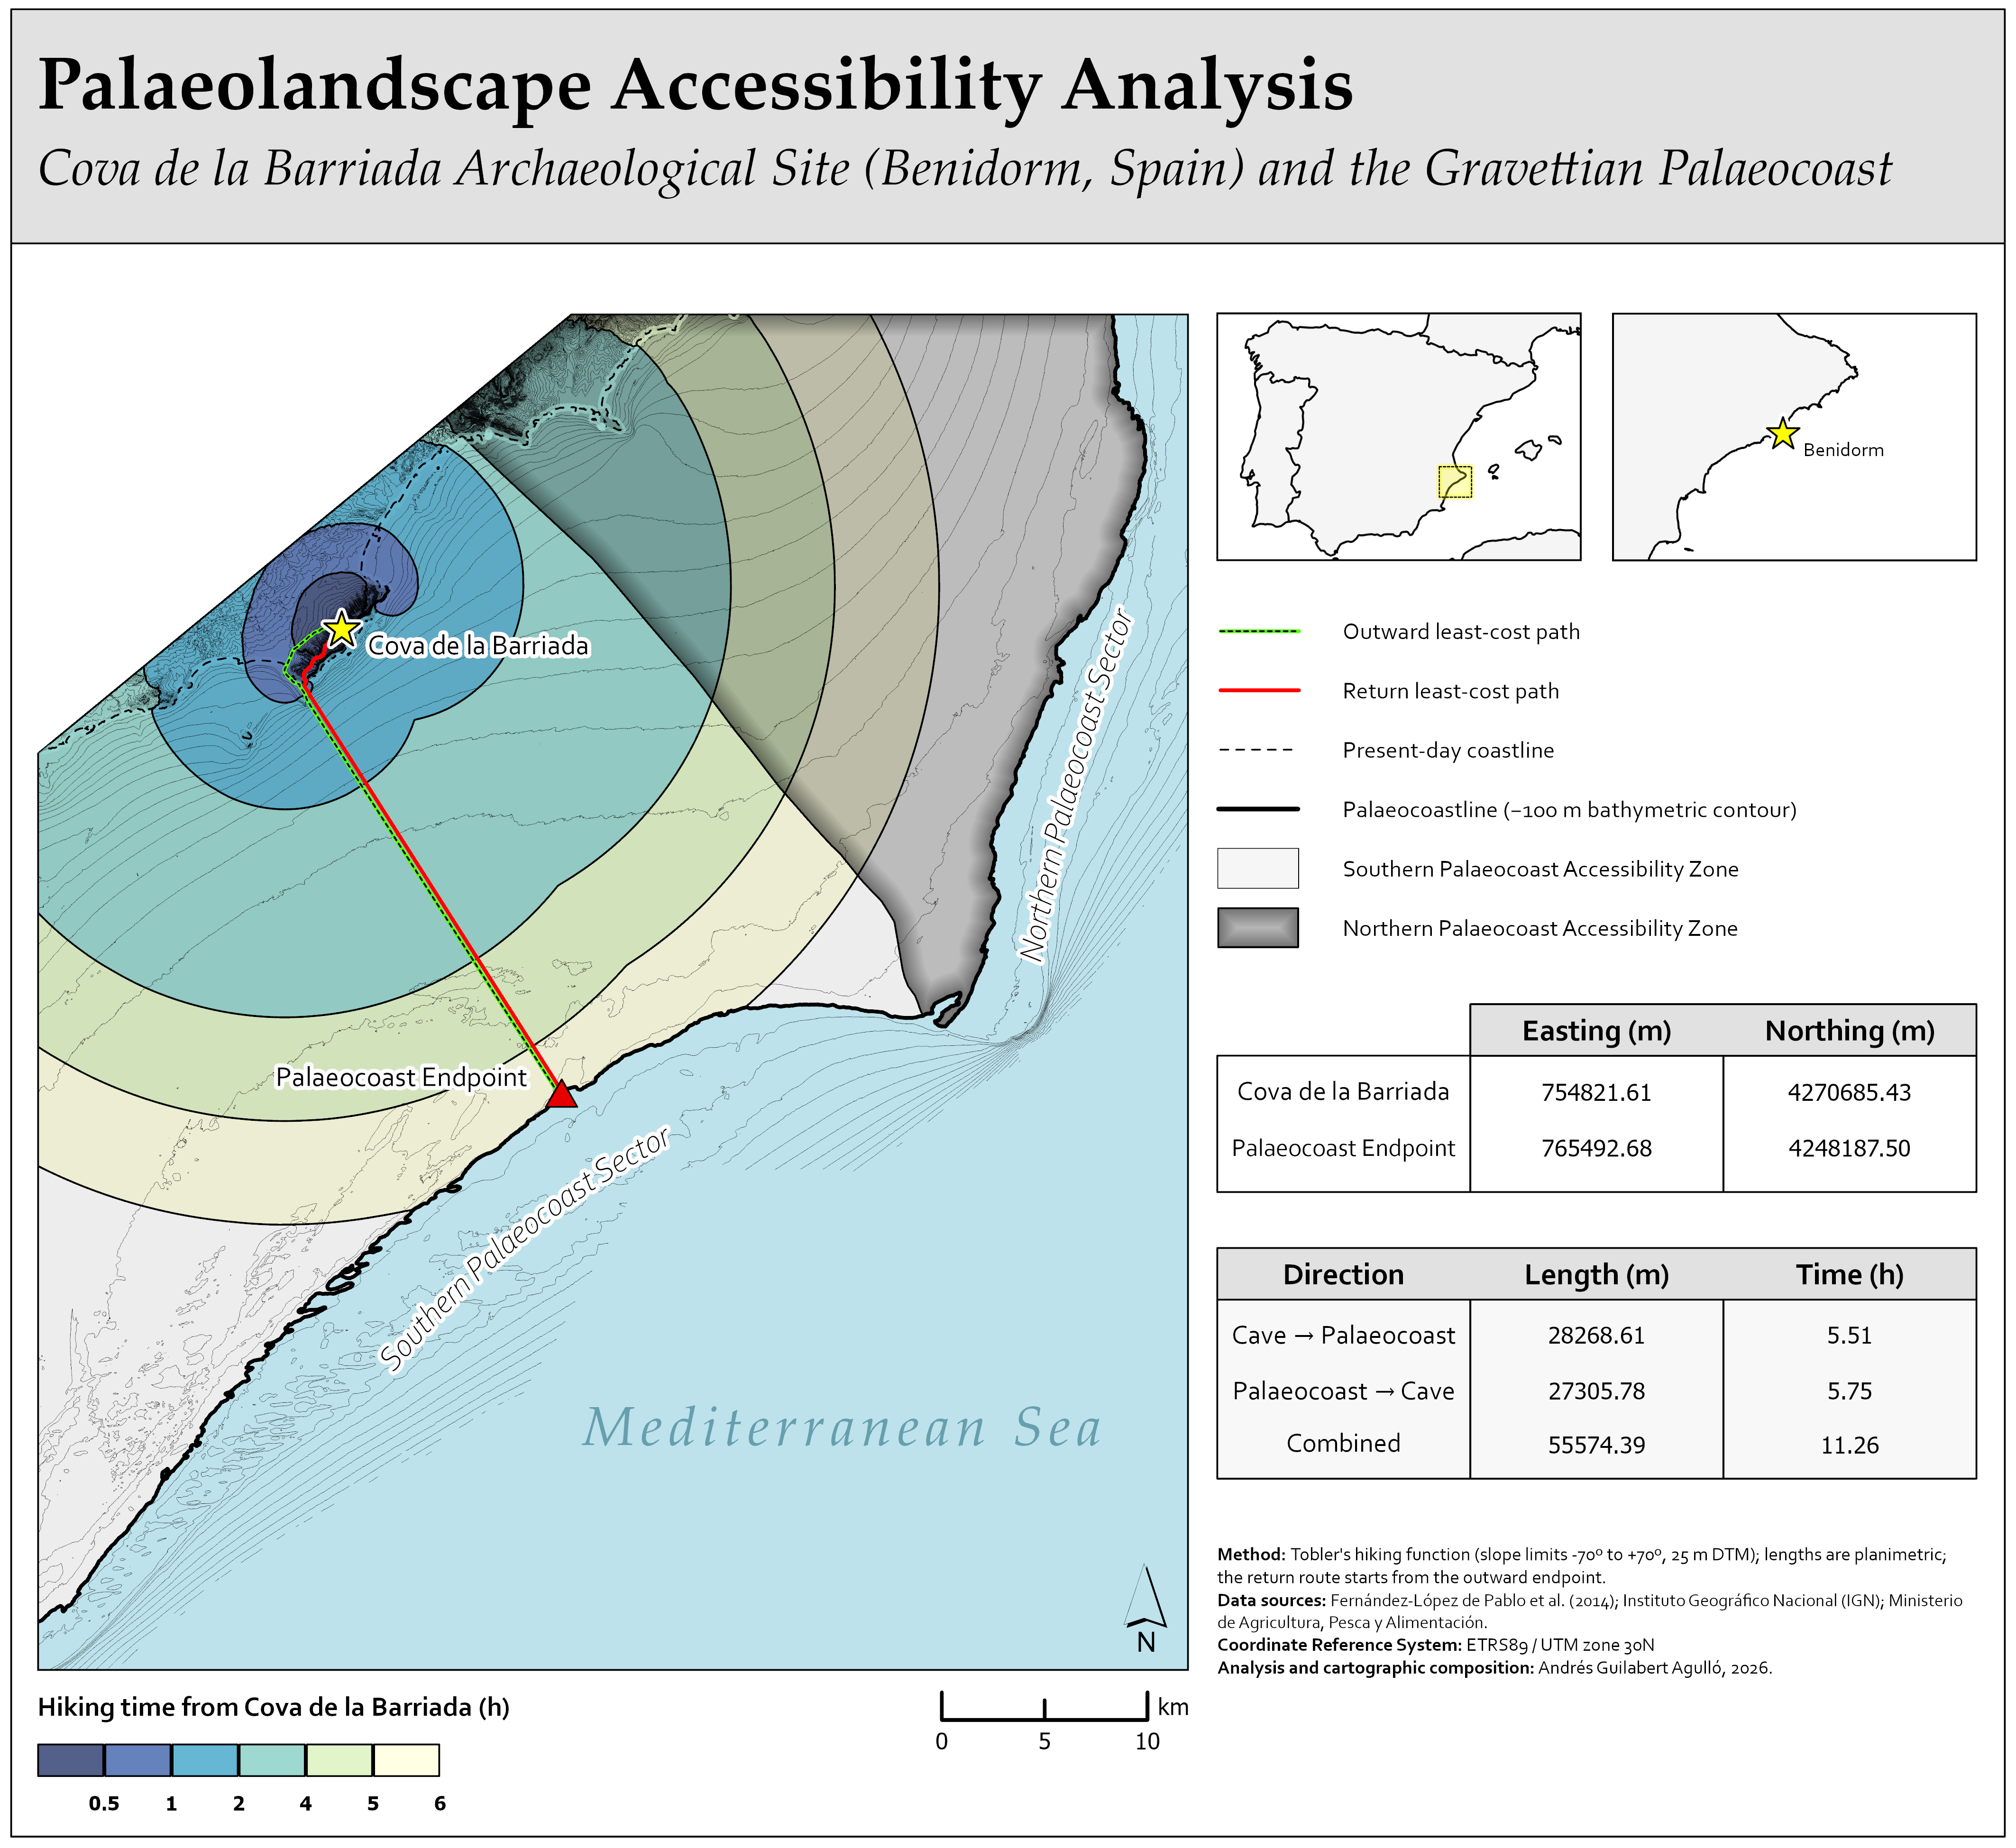

**Figure 8. Final Layout**

In [11]:
print("Starting Map and Layout Import...\n")

# --- IMPORT MAP TEMPLATE -----------------------------------------------
cova_map = aprx.importDocument(str(map_template))

# --- APPLY ISOCHRONE SYMBOLOGY ------------------------------------------
lyr = cova_map.listLayers("isochrones_cave")[0]
sym = lyr.symbology
sym.renderer.fields = ["ContourMax"]

for item in sym.renderer.groups[0].items:
    item.symbol.outlineWidth = 0.5
    item.symbol.outlineColor = {'RGB': [0, 0, 0, 100]}

lyr.symbology = sym

# --- IMPORT LAYOUT TEMPLATE ---------------------------------------------
cova_layout = aprx.importDocument(str(layout_template), reuse_existing_maps=True)

# --- UPDATE ROUTE LENGTHS AND TRAVEL TIMES -------------------------------
cova_layout.listElements("TEXT_ELEMENT", "cave_coast_length")[0].text = f"{length_outward_rounded:.2f}"
cova_layout.listElements("TEXT_ELEMENT", "cave_coast_time")[0].text = f"{time_outward_rounded:.2f}"
cova_layout.listElements("TEXT_ELEMENT", "coast_cave_length")[0].text = f"{length_return_rounded:.2f}"
cova_layout.listElements("TEXT_ELEMENT", "coast_cave_time")[0].text = f"{time_return_rounded:.2f}"
cova_layout.listElements("TEXT_ELEMENT", "combined_length")[0].text = f"{(length_outward_rounded + length_return_rounded):.2f}"
cova_layout.listElements("TEXT_ELEMENT", "combined_time")[0].text = f"{(time_outward_rounded + time_return_rounded):.2f}"

# --- UPDATE CAVE AND COAST ENDPOINT COORDINATES -------------------------
cova_layout.listElements("TEXT_ELEMENT", "cave_easting")[0].text = f"{x_cave:.2f}"
cova_layout.listElements("TEXT_ELEMENT", "cave_northing")[0].text = f"{y_cave:.2f}"
cova_layout.listElements("TEXT_ELEMENT", "coast_easting")[0].text = f"{x_coast:.2f}"
cova_layout.listElements("TEXT_ELEMENT", "coast_northing")[0].text = f"{y_coast:.2f}"

# --- UPDATE WORKFLOW PARAMETERS IN LAYOUT DESCRIPTION -------------------
text_description = cova_layout.listElements("TEXT_ELEMENT", "map_information")[0]
text_formatted = (
    text_description.text
    .replace("LOW_ANGLE", f"{LOW_ANGLE}")
    .replace("HIGH_ANGLE", f"{HIGH_ANGLE}")
    .replace("CELL_SIZE", f"{CELL_SIZE}")
)
text_description.text = text_formatted

# --- EXPORT FINAL LAYOUT AS HIGH-RESOLUTION PNG --------------------------
output_path = PROJECT_DIR / "OUTPUT" / "LAYOUT.png"
png = arcpy.mp.CreateExportFormat("PNG", str(output_path))
png.resolution = 600
cova_layout.export(png)

print(f"Output Layout Path: {output_path}\n")

# --- DISPLAY FINAL LAYOUT ------------------------------------------------
display(Image(filename=str(output_path)))
display(Markdown("**Figure 8. Final Layout**"))

<br>

# **Conclusions**

>The following section summarises the main findings of the accessibility analysis. Key findings are generated dynamically from the model outputs, ensuring that the conclusions remain consistent with the results obtained when the workflow is rerun with different parameters or input data.

In [15]:
display(Markdown(f"""
<br>

### ▸ Key Findings

> *Which sector of the Gravettian palaeocoast has the lowest modelled travel cost from Cova de la Barriada, and where is its Palaeocoast Endpoint and associated route?*

Under the reference configuration ({CELL_SIZE} m DTM; slope limits of {LOW_ANGLE}° to +{HIGH_ANGLE}°), the **{NEAR_SECTOR} Palaeocoast Sector** has the lowest modelled travel cost from the cave. Its **Palaeocoast Endpoint** is located at `{x_coast:.2f} E, {y_coast:.2f} N` (ETRS89 / UTM zone 30N).

| Route | Length (m) | Travel time (h) |
| --- | ---: | ---: |
| Cave → Palaeocoast | {length_outward_rounded:.2f} | {time_outward_rounded:.2f} |
| Palaeocoast → Cave | {length_return_rounded:.2f} | {time_return_rounded:.2f} |
| **Round trip** | **{(length_outward_rounded + length_return_rounded):.2f}** | **{time_outward_rounded + time_return_rounded}** |

### ▸ Limitations

These results show modelled accessibility, not actual travel behaviour. They should be interpreted with the following limitations in mind.

- **Sea level.** The palaeocoast is represented by the present-day −100 m bathymetric contour. Changes in sea level and coastline position since the Gravettian are not accounted for.
- **Terrain data and resolution.** The DTM was interpolated from modern topographic and bathymetric contour data, rather than a reconstruction of the Gravettian landscape. Some small-scale terrain features may also be missing due to the source data and the cell size. Vegetation and other landscape features are not modelled.
- **Cost function.** Tobler's hiking function estimates walking speed based on slope, so the calculated travel times should be treated as estimates rather than actual travel times.
- **Cave location.** The cave location was digitised from a published map and is approximate.
- **Sector definition.** The coastal sectors were delineated manually using the ridge in the `dist_accum_coast` surface. The Palaeocoast Endpoint was calculated using the full palaeocoast, but the sector assigned to it depends on the boundaries defined during this preparation step.

### ▸ References
- Fernández-López de Pablo, J., Badal, E., Ferrer García, C., Martínez-Ortí, A., & Sanchis Serra, A. (2014). Land snails as a diet diversification proxy during the Early Upper Palaeolithic in Europe. *PLOS ONE, 9*(8), e104898. https://doi.org/10.1371/journal.pone.0104898
- Instituto Geográfico Nacional. *BTN Product Specifications.* Retrieved July 2026, from https://www.ign.es/resources/docs/IGNCnig/BTN/ESPBTN.pdf
- Esri. *Topo To Raster (3D Analyst Tools).* ArcGIS Pro documentation. https://doc.esri.com/en/arcgis-pro/latest/tool-reference/3d-analyst/topo-to-raster.html
- Esri. *Distance Accumulation (Spatial Analyst Tools).* ArcGIS Pro documentation. https://doc.esri.com/en/arcgis-pro/latest/tool-reference/spatial-analyst/distance-accumulation.html
- Esri. *Optimal Path As Line (Spatial Analyst Tools).* ArcGIS Pro documentation. https://doc.esri.com/en/arcgis-pro/latest/tool-reference/spatial-analyst/optimal-path-as-line.html
- Tobler, W. (1993). *Three presentations on geographical analysis and modeling.* National Center for Geographic Information and Analysis.

Data sources, licences and access dates are documented in the *Data Acquisition* section.

"""))


<br>

### ▸ Key Findings

> *Which sector of the Gravettian palaeocoast has the lowest modelled travel cost from Cova de la Barriada, and where is its Palaeocoast Endpoint and associated route?*

Under the reference configuration (25 m DTM; slope limits of -70° to +70°), the **Southern Palaeocoast Sector** has the lowest modelled travel cost from the cave. Its **Palaeocoast Endpoint** is located at `765492.68 E, 4248187.50 N` (ETRS89 / UTM zone 30N).

| Route | Length (m) | Travel time (h) |
| --- | ---: | ---: |
| Cave → Palaeocoast | 28268.61 | 5.51 |
| Palaeocoast → Cave | 27305.78 | 5.75 |
| **Round trip** | **55574.39** | **11.26** |

### ▸ Limitations

These results show modelled accessibility, not actual travel behaviour. They should be interpreted with the following limitations in mind.

- **Sea level.** The palaeocoast is represented by the present-day −100 m bathymetric contour. Changes in sea level and coastline position since the Gravettian are not accounted for.
- **Terrain data and resolution.** The DTM was interpolated from modern topographic and bathymetric contour data, rather than a reconstruction of the Gravettian landscape. Some small-scale terrain features may also be missing due to the source data and the cell size. Vegetation and other landscape features are not modelled.
- **Cost function.** Tobler's hiking function estimates walking speed based on slope, so the calculated travel times should be treated as estimates rather than actual travel times.
- **Cave location.** The cave location was digitised from a published map and is approximate.
- **Sector definition.** The coastal sectors were delineated manually using the ridge in the `dist_accum_coast` surface. The Palaeocoast Endpoint was calculated using the full palaeocoast, but the sector assigned to it depends on the boundaries defined during this preparation step.

### ▸ References
- Fernández-López de Pablo, J., Badal, E., Ferrer García, C., Martínez-Ortí, A., & Sanchis Serra, A. (2014). Land snails as a diet diversification proxy during the Early Upper Palaeolithic in Europe. *PLOS ONE, 9*(8), e104898. https://doi.org/10.1371/journal.pone.0104898
- Instituto Geográfico Nacional. *BTN Product Specifications.* Retrieved July 2026, from https://www.ign.es/resources/docs/IGNCnig/BTN/ESPBTN.pdf
- Esri. *Topo To Raster (3D Analyst Tools).* ArcGIS Pro documentation. https://doc.esri.com/en/arcgis-pro/latest/tool-reference/3d-analyst/topo-to-raster.html
- Esri. *Distance Accumulation (Spatial Analyst Tools).* ArcGIS Pro documentation. https://doc.esri.com/en/arcgis-pro/latest/tool-reference/spatial-analyst/distance-accumulation.html
- Esri. *Optimal Path As Line (Spatial Analyst Tools).* ArcGIS Pro documentation. https://doc.esri.com/en/arcgis-pro/latest/tool-reference/spatial-analyst/optimal-path-as-line.html
- Tobler, W. (1993). *Three presentations on geographical analysis and modeling.* National Center for Geographic Information and Analysis.

Data sources, licences and access dates are documented in the *Data Acquisition* section.



In [ ]:
# --- OPEN MAP AND LAYOUT VIEWS -----------------------------------------
cova_map.openView()
cova_layout.openView()